<a href="https://colab.research.google.com/github/dhianab12-commits/machinelearningKNN/blob/main/Prediksi%20KNN%20Pola%20Asuh%20Untitled17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
# 1: INPUT DATA ---
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("=== TAHAP 1: INPUT DATA ===")
# Membaca file kuesioner pola asuh
df = pd.read_csv("/content/Data Kuesioner Pola Asuh.csv", sep=';')

# Menampilkan TABEL 5 baris pertama dari data mentah
print("Tabel Data Mentah Kuesioner (5 Baris Pertama):")
display(df.head())

print(f"\nTotal Keseluruhan Data: {len(df)} Responden")

=== TAHAP 1: INPUT DATA ===
Tabel Data Mentah Kuesioner (5 Baris Pertama):


,Nama Responden,Jenis Kelamin,Usia,Jumlah Anak,Total Skor (A-F),Normalisasi KNN,Total Pendidikan Ibu,Total Pendidikan Ayah,Total Pekerjaan Ibu,Total Pekerjaan Ayah,Total Pendapatan Keluarga,Total Asuransi Kesehatan,Total Pengeluaran Gizi Anak
0,AGNES NOVINCE YANDRI ANAIT,Perempuan,30,2,116,"0,396226415","0,5","0,75",0,"0,333333333",0,0,"0,333333333"
1,SARA OEMATAN,Perempuan,33,1,182,"0,811320755",1,"0,75",1,"0,333333333","0,333333333","0,5","0,666666667"
2,YATI KIRIBUNGA,Perempuan,40,5,160,"0,672955975","0,5","0,75",0,"0,166666667",0,0,1
3,GERTRUDIS LURUK,Perempuan,47,5,179,"0,79245283","0,75","0,75",0,"0,833333333","0,666666667",0,"0,666666667"
4,MARINCE O. DJO TALO,Perempuan,34,1,172,"0,748427673",1,1,1,"0,5","0,666666667","0,5","0,666666667"



Total Keseluruhan Data: 100 Responden


=== TAHAP 2: PRA-PEMROSESAN & NORMALISASI ===
Tabel Data Setelah Normalisasi (Rentang 0 - 1):


,Usia,Jumlah Anak,Total Pendidikan Ibu,Total Pendidikan Ayah,Total Pekerjaan Ibu,Total Pekerjaan Ayah,Total Pendapatan Keluarga,Total Asuransi Kesehatan,Total Pengeluaran Gizi Anak
0,0.275,0.25,0.333333,0.75,0.0,0.333333,0.000000,0.0,0.333333
1,0.350,0.00,1.000000,0.75,1.0,0.333333,0.333333,0.5,0.666667
2,0.525,1.00,0.333333,0.75,0.0,0.166667,0.000000,0.0,1.000000
3,0.700,1.00,0.666667,0.75,0.0,0.833333,0.666667,0.0,0.666667
4,0.375,0.00,1.000000,1.00,1.0,0.500000,0.666667,0.5,0.666667


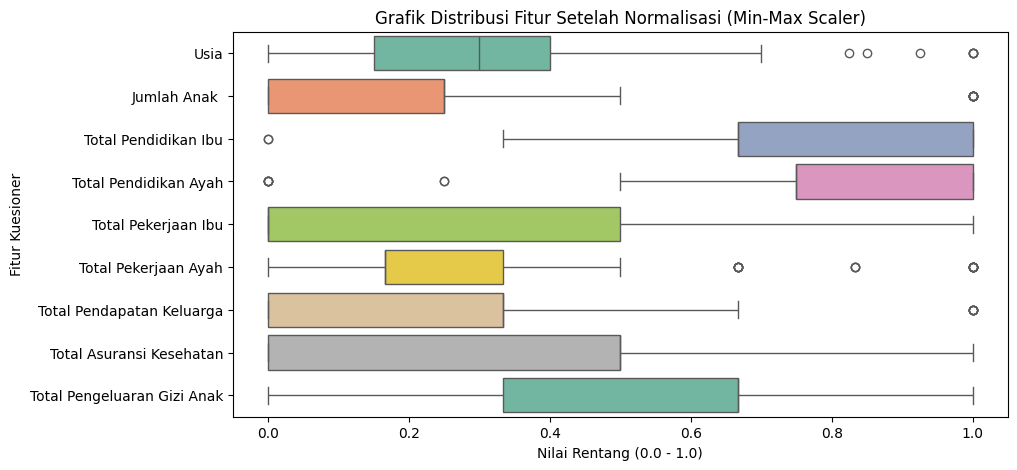

In [34]:
#  2: PRA-PEMROSESAN DATA ---
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

print("=== TAHAP 2: PRA-PEMROSESAN & NORMALISASI ===")
# 1. Cleaning: Ubah koma jadi titik
kolom_desimal = [
    'Total Pendidikan Ibu', 'Total Pendidikan Ayah',
    'Total Pekerjaan Ibu', 'Total Pekerjaan Ayah',
    'Total Pendapatan Keluarga', 'Total Asuransi Kesehatan',
    'Total Pengeluaran Gizi Anak'
]
for col in kolom_desimal:
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace(',', '.').astype(float)
df.fillna(0, inplace=True)

# 2. Pemilihan Fitur (X)
fitur_X = [
    'Usia', 'Jumlah Anak ', 'Total Pendidikan Ibu', 'Total Pendidikan Ayah',
    'Total Pekerjaan Ibu', 'Total Pekerjaan Ayah', 'Total Pendapatan Keluarga',
    'Total Asuransi Kesehatan', 'Total Pengeluaran Gizi Anak'
]
X_mentah = df[fitur_X]

# 3. Normalisasi Min-Max
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_mentah), columns=fitur_X)

# Menampilkan TABEL data yang sudah dinormalisasi
print("Tabel Data Setelah Normalisasi (Rentang 0 - 1):")
display(X.head())

# Menampilkan GRAFIK Boxplot Normalisasi
plt.figure(figsize=(10, 5))
sns.boxplot(data=X, orient="h", palette="Set2")
plt.title("Grafik Distribusi Fitur Setelah Normalisasi (Min-Max Scaler)")
plt.xlabel("Nilai Rentang (0.0 - 1.0)")
plt.ylabel("Fitur Kuesioner")
plt.show()

=== TAHAP 3: PELABELAN KELAS TARGET ===


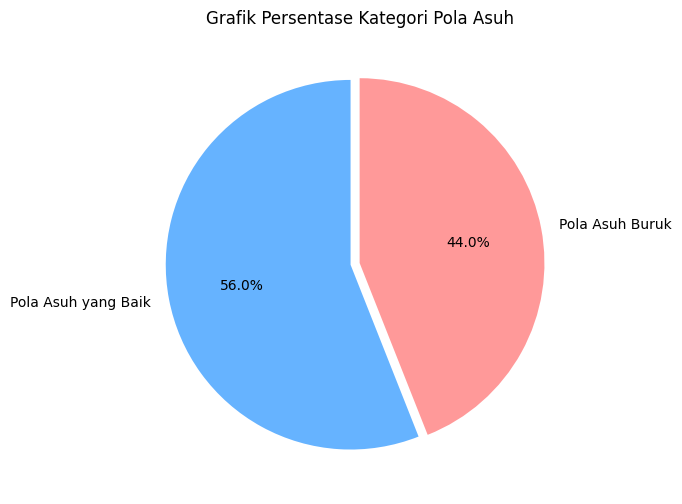


Tabel Jumlah Responden per Kategori:


,Jumlah Responden
Target_Kelas,
Pola Asuh yang Baik,56
Pola Asuh Buruk,44


In [35]:
#  3: PELABELAN DATA ---
print("=== TAHAP 3: PELABELAN KELAS TARGET ===")

# Fungsi Pelabelan (Batas skor 160 bisa disesuaikan dengan standar skripsi Anda)
def klasifikasi_pola_asuh(skor):
    if skor >= 160:
        return 'Pola Asuh yang Baik'
    else:
        return 'Pola Asuh Buruk'

df['Target_Kelas'] = df['Total Skor (A-F)'].apply(klasifikasi_pola_asuh)
y = df['Target_Kelas']

# Menghitung jumlah masing-masing kelas
jumlah_kelas = y.value_counts()

# Menampilkan GRAFIK Pie Chart Proporsi Kelas
plt.figure(figsize=(6, 6))
plt.pie(jumlah_kelas, labels=jumlah_kelas.index, autopct='%1.1f%%',
        startangle=90, colors=['#66b3ff','#ff9999'], explode=(0.05, 0))
plt.title('Grafik Persentase Kategori Pola Asuh')
plt.show()

# Menampilkan TABEL Frekuensi
print("\nTabel Jumlah Responden per Kategori:")
display(jumlah_kelas.to_frame(name="Jumlah Responden"))

=== TAHAP 4: PEMBAGIAN DATA LATIH & UJI ===


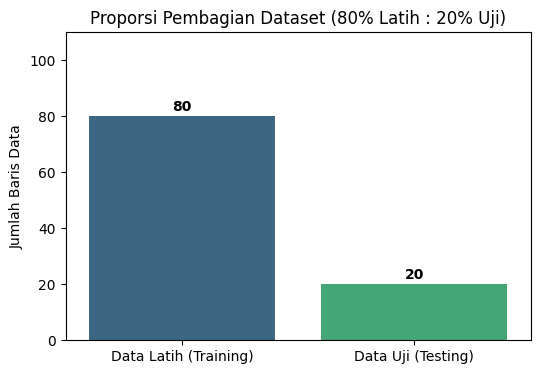

In [36]:
#  4: PEMBAGIAN DATASET ---
from sklearn.model_selection import train_test_split

print("=== TAHAP 4: PEMBAGIAN DATA LATIH & UJI ===")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Data untuk visualisasi
kategori_split = ['Data Latih (Training)', 'Data Uji (Testing)']
jumlah_split = [len(X_train), len(X_test)]

# Menampilkan GRAFIK Bar Chart Pembagian Data
plt.figure(figsize=(6, 4))
sns.barplot(x=kategori_split, y=jumlah_split, palette='viridis')
for i, v in enumerate(jumlah_split):
    plt.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.title("Proporsi Pembagian Dataset (80% Latih : 20% Uji)")
plt.ylabel("Jumlah Baris Data")
plt.ylim(0, len(X) + 10)
plt.show()

=== TAHAP 5: PENCARIAN NILAI K TERBAIK (HYPERPARAMETER TUNING) ===
✅ Mesin selesai menganalisis. Nilai K Terbaik adalah K=3 (Akurasi: 86.25%)


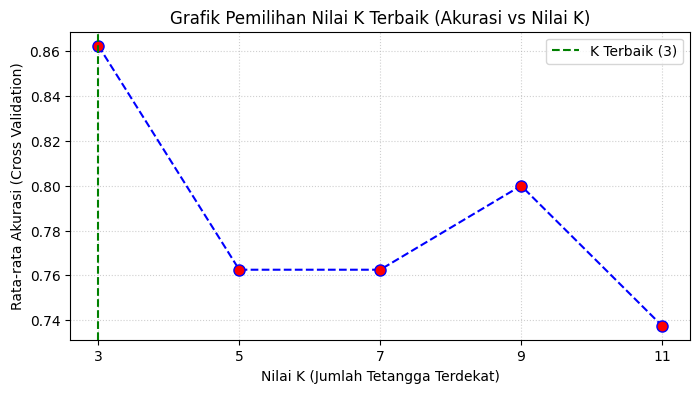


=== TAHAP 6: TRAINING FINAL & PREDIKSI ===
Model KNN Final berhasil dilatih menggunakan K=3!

Tabel Perbandingan Hasil Klasifikasi pada Data Uji:


,Nama Responden,Label Asli (Aktual),Tebakan Mesin (Prediksi),Status Tebakan
0,MARIA NURHAYATI,Pola Asuh yang Baik,Pola Asuh Buruk,❌ Salah
1,WILFRIDA TELIK SERAN,Pola Asuh yang Baik,Pola Asuh Buruk,❌ Salah
2,VERONICA DO SANTOS,Pola Asuh yang Baik,Pola Asuh Buruk,❌ Salah
3,MARLENI ROTELTA,Pola Asuh yang Baik,Pola Asuh yang Baik,✅ Benar
4,SILVIA DA COSTA,Pola Asuh Buruk,Pola Asuh Buruk,✅ Benar
5,TN. NDUN,Pola Asuh Buruk,Pola Asuh Buruk,✅ Benar
6,NI'MATUL HOERIYAH,Pola Asuh Buruk,Pola Asuh Buruk,✅ Benar
7,YULIANA DOKO,Pola Asuh yang Baik,Pola Asuh Buruk,❌ Salah
8,ARANCI KOROH,Pola Asuh Buruk,Pola Asuh Buruk,✅ Benar
9,NOFILIA ATOK,Pola Asuh Buruk,Pola Asuh Buruk,✅ Benar


In [37]:
#  5 & 6: PENCARIAN K TERBAIK, TRAINING, & PREDIKSI ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=== TAHAP 5: PENCARIAN NILAI K TERBAIK (HYPERPARAMETER TUNING) ===")

# 1. Menentukan rentang nilai K yang akan diuji (Bilangan ganjil 3 hingga 12)
# Menggunakan bilangan ganjil agar tidak terjadi hasil seri (tie-break) saat voting
k_range = range(3, 12, 2)
cv_scores = []

# 2. Mesin mencoba satu per satu nilai K dan mencatat akurasinya
for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    # Menguji dengan 5-Fold Cross Validation pada data latih
    scores = cross_val_score(knn_temp, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

# 3. Menentukan K dengan skor akurasi rata-rata paling tinggi
best_k = k_range[np.argmax(cv_scores)]
best_score = max(cv_scores)

print(f"✅ Mesin selesai menganalisis. Nilai K Terbaik adalah K={best_k} (Akurasi: {best_score * 100:.2f}%)")

# 4. Menampilkan GRAFIK Pergerakan Akurasi tiap nilai K
plt.figure(figsize=(8, 4))
plt.plot(k_range, cv_scores, marker='o', linestyle='dashed', color='blue', markerfacecolor='red', markersize=8)
plt.axvline(x=best_k, color='green', linestyle='--', label=f'K Terbaik ({best_k})')
plt.title('Grafik Pemilihan Nilai K Terbaik (Akurasi vs Nilai K)')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)')
plt.ylabel('Rata-rata Akurasi (Cross Validation)')
plt.xticks(k_range)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print("\n=== TAHAP 6: TRAINING FINAL & PREDIKSI ===")
# 5. Training Final menggunakan nilai K Terbaik yang ditemukan secara otomatis
knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn.fit(X_train, y_train)
print(f"Model KNN Final berhasil dilatih menggunakan K={best_k}!\n")

# 6. Prediksi pada Data Uji (Testing)
y_pred = knn.predict(X_test)

# 7. Menampilkan TABEL Komparasi Hasil (Nama, Aktual, vs Prediksi)
nama_responden_uji = df.loc[y_test.index, 'Nama Responden'].values
df_hasil_prediksi = pd.DataFrame({
    'Nama Responden': nama_responden_uji,
    'Label Asli (Aktual)': y_test.values,
    'Tebakan Mesin (Prediksi)': y_pred
})

df_hasil_prediksi['Status Tebakan'] = df_hasil_prediksi.apply(
    lambda row: '✅ Benar' if row['Label Asli (Aktual)'] == row['Tebakan Mesin (Prediksi)'] else '❌ Salah', axis=1
)

print(f"Tabel Perbandingan Hasil Klasifikasi pada Data Uji:")
display(df_hasil_prediksi.head(10))

=== TAHAP 7A: EVALUASI KINERJA & CONFUSION MATRIX PER NILAI K ===

--- CONFUSION MATRIX UNTUK K = 3 ---
Akurasi Sementara: 65.00%


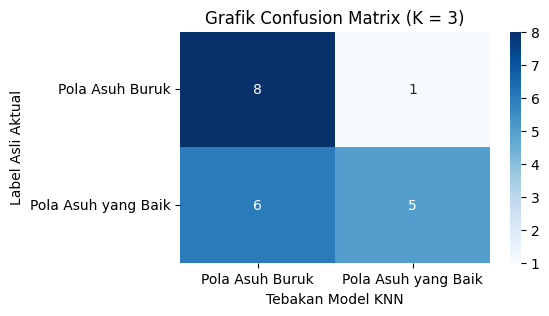


--- CONFUSION MATRIX UNTUK K = 5 ---
Akurasi Sementara: 80.00%


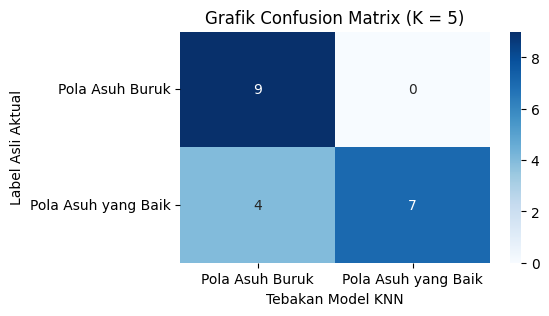


--- CONFUSION MATRIX UNTUK K = 7 ---
Akurasi Sementara: 85.00%


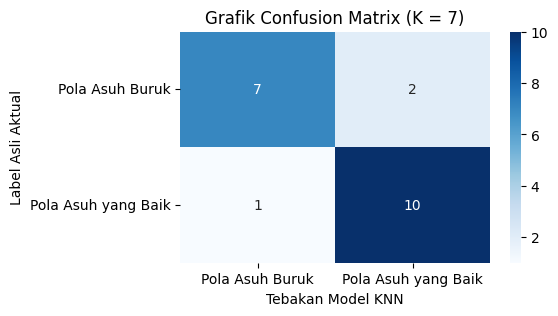


--- CONFUSION MATRIX UNTUK K = 9 ---
Akurasi Sementara: 90.00%


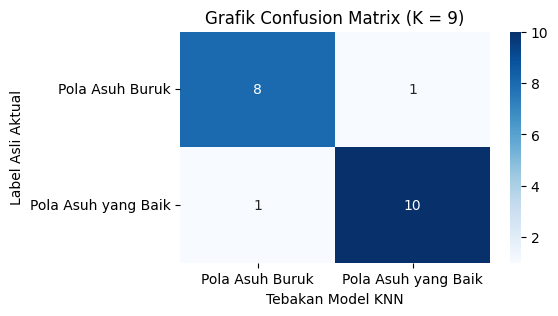


--- CONFUSION MATRIX UNTUK K = 11 ---
Akurasi Sementara: 90.00%


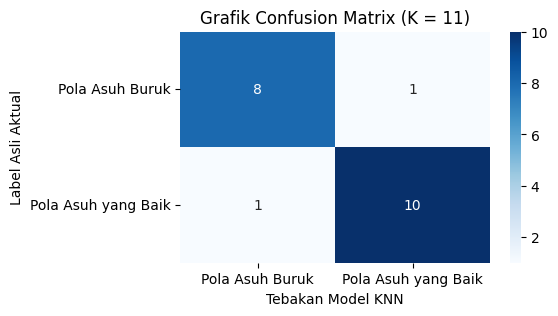


=== RINGKASAN: GRAFIK PERGERAKAN METRIK TIAP K ===


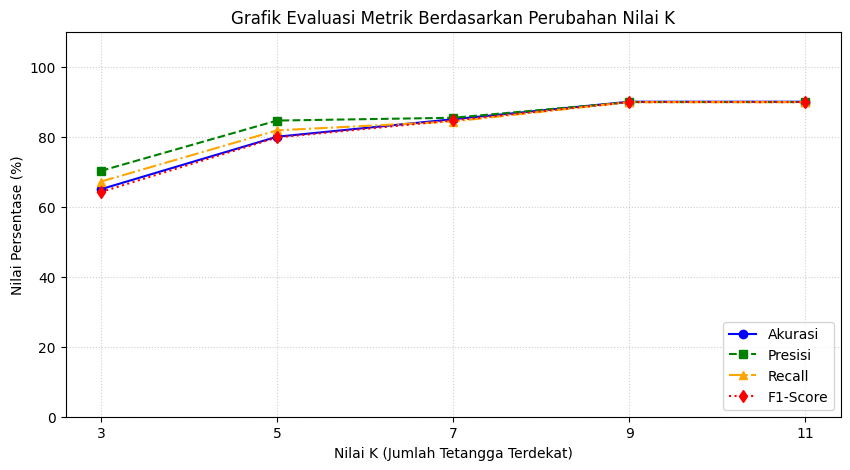


--- HASIL DETAIL UNTUK MODEL FINAL (K=3) ---
Akurasi (Accuracy) : 65.00%
Presisi (Precision): 70.24%
Recall             : 67.17%
F1-Score)          : 64.19%


In [39]:
#  7A: EVALUASI METRIK & CONFUSION MATRIX PER NILAI K ---
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import matplotlib.pyplot as plt

print("=== TAHAP 7A: EVALUASI KINERJA & CONFUSION MATRIX PER NILAI K ===")

k_range = range(3, 12, 2) # Menguji K=3, 5, 7, 9, 11
acc_list, prec_list, rec_list, f1_list = [], [], [], []

# ====================================================================
# 1. PENGUJIAN DAN CONFUSION MATRIX UNTUK SETIAP NILAI K
# ====================================================================
for k_uji in k_range:
    # Latih dan prediksi sementara untuk tiap K
    knn_temp = KNeighborsClassifier(n_neighbors=k_uji, metric='euclidean')
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)

    # Hitung dan Simpan metrik
    acc_temp = accuracy_score(y_test, y_pred_temp) * 100
    acc_list.append(acc_temp)
    prec_list.append(precision_score(y_test, y_pred_temp, average='macro', zero_division=0) * 100)
    rec_list.append(recall_score(y_test, y_pred_temp, average='macro', zero_division=0) * 100)
    f1_list.append(f1_score(y_test, y_pred_temp, average='macro', zero_division=0) * 100)

    # --- Menampilkan Confusion Matrix untuk K yang sedang diuji ---
    print(f"\n--- CONFUSION MATRIX UNTUK K = {k_uji} ---")
    print(f"Akurasi Sementara: {acc_temp:.2f}%")

    cm = confusion_matrix(y_test, y_pred_temp, labels=knn_temp.classes_)
    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=knn_temp.classes_, yticklabels=knn_temp.classes_)
    plt.xlabel('Tebakan Model KNN')
    plt.ylabel('Label Asli Aktual')
    plt.title(f'Grafik Confusion Matrix (K = {k_uji})')
    plt.show()

# ====================================================================
# 2. GRAFIK PERGERAKAN METRIK KESELURUHAN (LINE CHART)
# ====================================================================
print("\n=== RINGKASAN: GRAFIK PERGERAKAN METRIK TIAP K ===")
plt.figure(figsize=(10, 5))
plt.plot(k_range, acc_list, label='Akurasi', marker='o', linestyle='-', color='blue')
plt.plot(k_range, prec_list, label='Presisi', marker='s', linestyle='--', color='green')
plt.plot(k_range, rec_list, label='Recall', marker='^', linestyle='-.', color='orange')
plt.plot(k_range, f1_list, label='F1-Score', marker='d', linestyle=':', color='red')

plt.title('Grafik Evaluasi Metrik Berdasarkan Perubahan Nilai K')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)')
plt.ylabel('Nilai Persentase (%)')
plt.xticks(k_range)
plt.ylim(0, 110)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# ====================================================================
# 3. EVALUASI DETAIL UNTUK MODEL FINAL TERBAIK
# ====================================================================
print(f"\n--- HASIL DETAIL UNTUK MODEL FINAL (K={best_k}) ---")
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Akurasi (Accuracy) : {acc * 100:.2f}%")
print(f"Presisi (Precision): {prec * 100:.2f}%")
print(f"Recall             : {rec * 100:.2f}%")
print(f"F1-Score)          : {f1 * 100:.2f}%")

=== TAHAP 7B: PENGUJIAN KESTABILAN (CROSS VALIDATION PER NILAI K) ===

--- Hasil Uji untuk K = 3 ---
Fold 1 = 95.00%
Fold 2 = 90.00%
Fold 3 = 90.00%
Fold 4 = 100.00%
Fold 5 = 65.00%
>> Rata-rata Akurasi (K=3): 88.00%

--- Hasil Uji untuk K = 5 ---
Fold 1 = 80.00%
Fold 2 = 70.00%
Fold 3 = 90.00%
Fold 4 = 90.00%
Fold 5 = 65.00%
>> Rata-rata Akurasi (K=5): 79.00%

--- Hasil Uji untuk K = 7 ---
Fold 1 = 95.00%
Fold 2 = 75.00%
Fold 3 = 75.00%
Fold 4 = 90.00%
Fold 5 = 50.00%
>> Rata-rata Akurasi (K=7): 77.00%

--- Hasil Uji untuk K = 9 ---
Fold 1 = 85.00%
Fold 2 = 85.00%
Fold 3 = 80.00%
Fold 4 = 85.00%
Fold 5 = 50.00%
>> Rata-rata Akurasi (K=9): 77.00%

--- Hasil Uji untuk K = 11 ---
Fold 1 = 80.00%
Fold 2 = 60.00%
Fold 3 = 55.00%
Fold 4 = 85.00%
Fold 5 = 45.00%
>> Rata-rata Akurasi (K=11): 65.00%


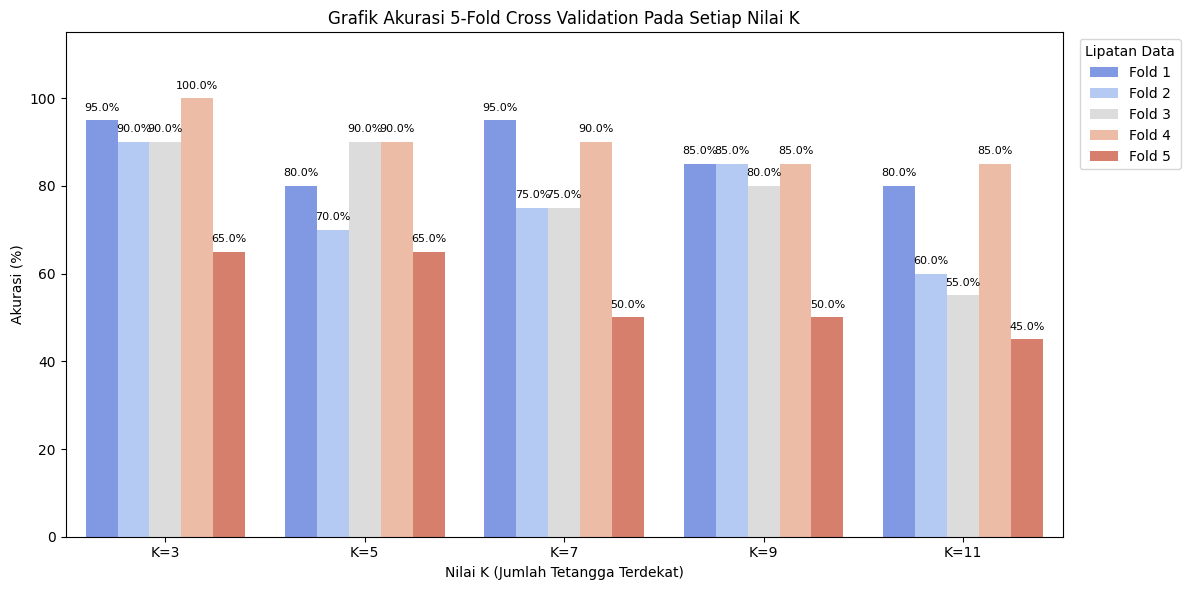

In [42]:
#  7B: CROSS VALIDATION UNTUK SETIAP NILAI K
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("=== TAHAP 7B: PENGUJIAN KESTABILAN (CROSS VALIDATION PER NILAI K) ===")

# Tentukan rentang K yang ingin diuji (misal: bilangan ganjil 3 sampai 11)
k_range = range(3, 12, 2)

# List kosong untuk menyimpan semua hasil agar bisa dijadikan grafik
semua_hasil_cv = []

# 1. MENGHITUNG CROSS VALIDATION UNTUK TIAP K
for k_uji in k_range:
    print(f"\n--- Hasil Uji untuk K = {k_uji} ---")
    knn_temp = KNeighborsClassifier(n_neighbors=k_uji, metric='euclidean')

    # Menjalankan 5-Fold Cross Validation (menggunakan seluruh fitur X dan target y)
    cv_scores = cross_val_score(knn_temp, X, y, cv=5, scoring='accuracy')
    cv_scores_percent = cv_scores * 100

    # Menampilkan hasil tiap lipatan
    for i, skor in enumerate(cv_scores_percent, 1):
        print(f"Fold {i} = {skor:.2f}%")
        # Menyimpan data untuk grafik
        semua_hasil_cv.append({
            'Nilai K': f'K={k_uji}',
            'Lipatan': f'Fold {i}',
            'Akurasi (%)': skor
        })

    rata_rata_cv = cv_scores_percent.mean()
    print(f">> Rata-rata Akurasi (K={k_uji}): {rata_rata_cv:.2f}%")

# ====================================================================
# 2. MENAMPILKAN GRAFIK DIAGRAM BATANG BERKELOMPOK (GROUPED BAR CHART)
# ====================================================================
# Mengubah list data menjadi format tabel (DataFrame)
df_cv = pd.DataFrame(semua_hasil_cv)

plt.figure(figsize=(12, 6))
# Membuat diagram batang berkelompok berdasarkan Nilai K dan Lipatan (Fold)
bars = sns.barplot(data=df_cv, x='Nilai K', y='Akurasi (%)', hue='Lipatan', palette='coolwarm')

# Menambahkan angka persentase tepat di atas setiap batang
for p in bars.patches:
    if p.get_height() > 0: # Mencegah error jika ada batang yang bernilai kosong
        bars.annotate(format(p.get_height(), '.1f') + '%',
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=8)

plt.title('Grafik Akurasi 5-Fold Cross Validation Pada Setiap Nilai K')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)')
plt.ylabel('Akurasi (%)')
plt.ylim(0, 115) # Diberi ruang hingga 115 agar tulisan angka tidak terpotong garis atas
plt.legend(title='Lipatan Data', bbox_to_anchor=(1.01, 1), loc='upper left') # Memindahkan legenda ke luar grafik
plt.tight_layout() # Merapikan tata letak agar grafik tidak terpotong
plt.show()

In [43]:
# --- CELL 8: OUTPUT SISTEM ---
import pandas as pd

print("=== TAHAP 8: OUTPUT SISTEM (SIMULASI 5 DATA BARU) ===")

# 1. Simulasi data isian kuesioner dari 5 responden/keluarga yang belum pernah ada
# Anda dapat mengubah angka-angka dan nama di bawah ini sesuai kebutuhan
data_kuesioner_baru = pd.DataFrame({
    'Nama Responden': ['Ibu Aminah', 'Ibu Maria', 'Ibu Yuliana', 'Ibu Ratna', 'Ibu Leni'],
    'Usia': [27, 32, 24, 35, 29],
    'Jumlah Anak ': [1, 3, 1, 4, 2],
    'Total Pendidikan Ibu': [0.75, 0.5, 1.0, 0.25, 0.75],
    'Total Pendidikan Ayah': [0.75, 0.5, 0.75, 0.5, 1.0],
    'Total Pekerjaan Ibu': [0.5, 0.0, 1.0, 0.0, 0.5],
    'Total Pekerjaan Ayah': [0.33, 0.66, 1.0, 0.33, 0.66],
    'Total Pendapatan Keluarga': [0.33, 0.0, 0.66, 0.33, 1.0],
    'Total Asuransi Kesehatan': [1.0, 0.0, 1.0, 0.5, 1.0],
    'Total Pengeluaran Gizi Anak': [0.66, 0.33, 1.0, 0.33, 0.66]
})

print("Tabel Input Data Karakteristik 5 Keluarga Baru:")
display(data_kuesioner_baru)

# 2. Memisahkan kolom 'Nama Responden' agar tidak ikut masuk ke perhitungan jarak (KNN hanya menerima angka)
nama_baru = data_kuesioner_baru['Nama Responden']
fitur_baru = data_kuesioner_baru.drop(columns=['Nama Responden'])

# 3. Proses Normalisasi (menggunakan scaler dari tahap sebelumnya)
data_baru_norm = scaler.transform(fitur_baru)

# 4. Proses Prediksi KNN untuk 5 data sekaligus
hasil_prediksi = knn.predict(data_baru_norm)

# 5. Menggabungkan Nama dan Hasil Prediksi ke dalam tabel akhir
df_hasil_akhir = pd.DataFrame({
    'Nama Responden': nama_baru,
    'Kesimpulan Prediksi KNN': hasil_prediksi
})

print("\n---------------------------------------------------------")
print("HASIL PREDIKSI SISTEM UNTUK 5 KELUARGA BARU:")
print("---------------------------------------------------------")
display(df_hasil_akhir)

# Menampilkan ringkasan berupa teks
print("\nRingkasan Hasil:")
for index, row in df_hasil_akhir.iterrows():
    print(f"- Keluarga {row['Nama Responden']} diprediksi menerapkan >> **{row['Kesimpulan Prediksi KNN'].upper()}**")

=== TAHAP 8: OUTPUT SISTEM (SIMULASI 5 DATA BARU) ===
Tabel Input Data Karakteristik 5 Keluarga Baru:


,Nama Responden,Usia,Jumlah Anak,Total Pendidikan Ibu,Total Pendidikan Ayah,Total Pekerjaan Ibu,Total Pekerjaan Ayah,Total Pendapatan Keluarga,Total Asuransi Kesehatan,Total Pengeluaran Gizi Anak
0,Ibu Aminah,27,1,0.75,0.75,0.5,0.33,0.33,1.0,0.66
1,Ibu Maria,32,3,0.50,0.50,0.0,0.66,0.00,0.0,0.33
2,Ibu Yuliana,24,1,1.00,0.75,1.0,1.00,0.66,1.0,1.00
3,Ibu Ratna,35,4,0.25,0.50,0.0,0.33,0.33,0.5,0.33
4,Ibu Leni,29,2,0.75,1.00,0.5,0.66,1.00,1.0,0.66



---------------------------------------------------------
HASIL PREDIKSI SISTEM UNTUK 5 KELUARGA BARU:
---------------------------------------------------------


,Nama Responden,Kesimpulan Prediksi KNN
0,Ibu Aminah,Pola Asuh Buruk
1,Ibu Maria,Pola Asuh Buruk
2,Ibu Yuliana,Pola Asuh Buruk
3,Ibu Ratna,Pola Asuh Buruk
4,Ibu Leni,Pola Asuh Buruk



Ringkasan Hasil:
- Keluarga Ibu Aminah diprediksi menerapkan >> **POLA ASUH BURUK**
- Keluarga Ibu Maria diprediksi menerapkan >> **POLA ASUH BURUK**
- Keluarga Ibu Yuliana diprediksi menerapkan >> **POLA ASUH BURUK**
- Keluarga Ibu Ratna diprediksi menerapkan >> **POLA ASUH BURUK**
- Keluarga Ibu Leni diprediksi menerapkan >> **POLA ASUH BURUK**
